
# MCMEA v3: Oracle-Mode Governance Evolution with Structural Profiles

## Purpose

This notebook implements **MCMEA v3** in **oracle mode**.

The model is **not** designed to advocate:
- democracy over dictatorship,
- dictatorship over democracy,
- East over West,
- or any fixed normative ranking.

Instead, it is designed to explore **how governance configurations evolve under structural pressures** while remaining disciplined about uncertainty.

---

## Core principle

This notebook follows a strict modeling rule:

> **Encode constraints and tendencies, not conclusions.**

That means:

- regions are **not** hardcoded to fixed governance outcomes,
- regimes are **not** declared morally superior,
- and the model must be allowed to produce variation, reversals, and mixed trajectories.

---

## What MCMEA is

**MCMEA** stands for **Markov-Chain Macrostate Evolutionary Algorithm**.

It combines:

1. **Evolutionary search** over governance configurations in an **S-Z space**
   - **S** = state capacity
   - **Z** = institutional constraint

2. **Markov macrostate analysis**
   - persistence
   - switching
   - basin stability
   - transition likelihood

This lets governance be modeled as a **dynamic equilibrium landscape** rather than a static institutional scorecard.

---

## Why v3 was needed

Earlier MCMEA versions helped reveal two problems:

1. **Smoothing could erase regime competition**
2. **One basin could dominate too easily if the landscape geometry favored it**

Your signal-noise research also added an important lesson:

> Search outcomes should not be trusted unless the competing structures remain distinguishable under noise.

So this version incorporates:

- explicit regime competition
- signal-noise diagnostics
- adaptive search
- **structural profiles** that shape context, not outcomes
- **persistent context dynamics** rather than i.i.d. shocks

---

## What structural profiles mean

This notebook uses three example structural profiles:

- **east**
- **anglo**
- **europe**

These are **not identities** and **not doctrines**.

They are modeled as **different prior distributions over context**:
- threat,
- volatility,
- polarization.

This means profiles shape the **game environment**, not the winner directly.

So:

- an eastern profile may tend to generate conditions more favorable to strong-S responses,
- an anglo profile may produce conditions more favorable to stronger constraint or fragmentation,
- a european profile may produce more balanced conditions,

but none of these are mandatory. The model is allowed to generate:
- strong Z in east,
- strong S in anglo settings,
- instability in europe,
- and mixed or hybrid outcomes everywhere.

---

## What this notebook tries to show

This notebook tries to answer a more disciplined question:

> Given historically plausible structural tendencies, what kinds of governance basins emerge, persist, and switch under noisy, evolving conditions?

It does **not** claim that the output is truth.
It treats the model as an **oracle under constraints**:
- useful if it respects reality,
- suspect if it bakes in conclusions,
- and honest only if it reports distinguishability and uncertainty.



In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## Helper functions

In [2]:

def clamp(x, lo=0.0, hi=1.0):
    return max(lo, min(hi, x))


def shannon_entropy(probs):
    probs = np.asarray(probs, dtype=float)
    probs = probs[probs > 0]
    if len(probs) == 0:
        return 0.0
    return float(-np.sum(probs * np.log(probs)))


def kendall_tau_from_ranks(r1, r2):
    n = len(r1)
    if n < 2:
        return 0.0

    concordant = 0
    discordant = 0
    for i in range(n):
        for j in range(i + 1, n):
            a = r1[i] - r1[j]
            b = r2[i] - r2[j]
            if a * b > 0:
                concordant += 1
            elif a * b < 0:
                discordant += 1

    denom = concordant + discordant
    return float((concordant - discordant) / denom) if denom > 0 else 0.0


def gaussian_peak(S, Z, muS, muZ, wS=0.18, wZ=0.18):
    return np.exp(-((S - muS) ** 2 / (2 * wS ** 2) + (Z - muZ) ** 2 / (2 * wZ ** 2)))


def softmax(x, temp=1.0):
    x = np.asarray(x, dtype=float)
    x = x / max(temp, 1e-8)
    x = x - np.max(x)
    ex = np.exp(x)
    return ex / np.sum(ex)


## Optional decomposition of institutional constraint

In [3]:

USE_Z_COMPONENTS = True
W_ROL = 0.70
W_DA = 0.30


def compose_Z(rol, da):
    return clamp(W_ROL * rol + W_DA * da, 0.0, 1.0)



## Structural profiles

Profiles shape the **distribution of context**, not the final governance regime directly.


In [4]:

PROFILE_NAMES = ["east", "anglo", "europe"]


def sample_structural_profile(rng):
    return str(rng.choice(PROFILE_NAMES))


def sample_beta_context(rng, profile):
    if profile == "east":
        threat = rng.beta(2.6, 2.0)
        volatility = rng.beta(2.2, 2.2)
        polarization = rng.beta(2.0, 2.3)

    elif profile == "anglo":
        threat = rng.beta(2.0, 2.5)
        volatility = rng.beta(2.2, 2.2)
        polarization = rng.beta(2.4, 2.0)

    elif profile == "europe":
        threat = rng.beta(2.1, 2.1)
        volatility = rng.beta(2.1, 2.1)
        polarization = rng.beta(2.1, 2.1)

    else:
        threat = rng.beta(2.0, 2.0)
        volatility = rng.beta(2.0, 2.0)
        polarization = rng.beta(2.0, 2.0)

    return {
        "threat": float(threat),
        "volatility": float(volatility),
        "polarization": float(polarization),
    }


def evolve_context(prev, rng, profile, rho=0.85, shock=0.08):
    base = sample_beta_context(rng, profile)
    out = {}
    for k in ["threat", "volatility", "polarization"]:
        val = rho * prev[k] + (1 - rho) * base[k] + rng.normal(0, shock)
        out[k] = clamp(val, 0.0, 1.0)
    return out


## Noise model

In [5]:

def beta_scalar(ctx):
    return (
        0.10 * (ctx["threat"] - 0.5)
        - 0.08 * (ctx["volatility"] - 0.5)
        - 0.06 * (ctx["polarization"] - 0.5)
    )


def sigma_ctx(ctx, sigma0=0.10, w_vol=0.18, w_pol=0.16, w_thr=0.06):
    return float(
        sigma0
        + w_vol * ctx["volatility"]
        + w_pol * ctx["polarization"]
        + w_thr * ctx["threat"]
    )



## Governance topology scores

Important: these are **not region-specific outcomes**.
Profiles influence context, while topology scores respond to context.


In [6]:

def topology_scores(S, Z, ctx):
    threat = ctx["threat"]
    volatility = ctx["volatility"]
    polarization = ctx["polarization"]

    # A: strong S
    peak_A = 1.20 * gaussian_peak(S, Z, muS=0.82, muZ=0.38, wS=0.16, wZ=0.18)

    # B: strong S & Z, made more conditional than before
    peak_B = 1.15 * gaussian_peak(S, Z, muS=0.80, muZ=0.80, wS=0.14, wZ=0.14)

    # C: strong Z
    peak_C = 1.20 * gaussian_peak(S, Z, muS=0.42, muZ=0.84, wS=0.18, wZ=0.16)

    ctx_A = (
        0.42 * threat
        + 0.22 * volatility
        - 0.08 * polarization
    )

    ctx_B = (
        0.18 * (1 - volatility)
        + 0.15 * (1 - polarization)
        - 0.20 * threat
        - 0.15 * abs(threat - 0.5)
    )

    ctx_C = (
        0.36 * (1 - threat)
        + 0.18 * (1 - volatility)
        - 0.08 * polarization
    )

    b = beta_scalar(ctx)

    Q_A = peak_A + ctx_A + b
    Q_B = peak_B + ctx_B + b
    Q_C = peak_C + ctx_C + b

    return {
        "A_Strong_S": float(Q_A),
        "B_Strong_SZ": float(Q_B),
        "C_Strong_Z": float(Q_C),
    }


def governance_latent_components(S, Z, ctx):
    return topology_scores(S, Z, ctx)


## Noisy observation and regime resolution

In [7]:

def observe_regime_scores(S, Z, ctx, rng, m=5, lam=1.0):
    comps = governance_latent_components(S, Z, ctx)
    sig = sigma_ctx(ctx)

    obs = {}
    for name, q in comps.items():
        vals = q + rng.normal(0.0, sig, size=m)
        mu = float(np.mean(vals))
        sd = float(np.std(vals, ddof=0))
        robust = float(mu - lam * sd)
        obs[name] = {
            "latent": q,
            "mean": mu,
            "std": sd,
            "robust": robust,
        }
    return obs, sig


def regime_resolution(obs, sigma_eff):
    latents = sorted(
        [(k, v["latent"]) for k, v in obs.items()],
        key=lambda x: x[1],
        reverse=True
    )
    if len(latents) < 2:
        return {"R": 0.0, "delta": 0.0, "top1": None, "top2": None}

    top1, q1 = latents[0]
    top2, q2 = latents[1]
    delta = float(q1 - q2)
    R = float(delta / sigma_eff) if sigma_eff > 0 else 0.0
    return {"R": R, "delta": delta, "top1": top1, "top2": top2}


def select_regime_from_obs(obs, mode="robust_max", rng=None, temp=1.0):
    keys = list(obs.keys())

    if mode == "latent_max":
        return max(keys, key=lambda k: obs[k]["latent"])

    if mode == "robust_max":
        return max(keys, key=lambda k: obs[k]["robust"])

    if mode == "stochastic_robust":
        scores = np.array([obs[k]["robust"] for k in keys], dtype=float)
        probs = softmax(scores, temp=temp)
        idx = rng.choice(len(keys), p=probs)
        return keys[idx]

    raise ValueError(f"Unknown mode: {mode}")



## Macrostate classification

B is now defined more strictly.
This avoids swallowing moderate upper-right outcomes too quickly.


In [8]:

def classify_point(S, Z):
    if S >= 0.72 and Z <= 0.52:
        return "A_Strong_S"
    if S >= 0.75 and Z >= 0.75:
        return "B_Strong_SZ"
    if Z >= 0.75 and S <= 0.52:
        return "C_Strong_Z"
    return "Hybrid"


## Evolutionary mechanics

In [9]:

def init_ind(rng):
    if USE_Z_COMPONENTS:
        return {"S": rng.random(), "rol": rng.random(), "da": rng.random()}
    return {"S": rng.random(), "Z": rng.random()}


def get_SZ(ind):
    if USE_Z_COMPONENTS:
        return ind["S"], compose_Z(ind["rol"], ind["da"])
    return ind["S"], ind["Z"]


def mutate(ind, rng, p=0.75, sigma=0.09):
    child = ind.copy()
    if rng.random() > p:
        return child

    if USE_Z_COMPONENTS:
        child["S"] = clamp(child["S"] + rng.normal(0, sigma))
        child["rol"] = clamp(child["rol"] + rng.normal(0, sigma))
        child["da"] = clamp(child["da"] + rng.normal(0, sigma))
    else:
        child["S"] = clamp(child["S"] + rng.normal(0, sigma))
        child["Z"] = clamp(child["Z"] + rng.normal(0, sigma))
    return child


def crossover(a, b, rng, alpha=0.45):
    def mix(x, y):
        t = rng.uniform(-alpha, 1 + alpha)
        return clamp((1 - t) * x + t * y)

    c1, c2 = a.copy(), b.copy()

    if USE_Z_COMPONENTS:
        for k in ["S", "rol", "da"]:
            c1[k] = mix(a[k], b[k])
            c2[k] = mix(b[k], a[k])
    else:
        for k in ["S", "Z"]:
            c1[k] = mix(a[k], b[k])
            c2[k] = mix(b[k], a[k])

    return c1, c2


def tournament(pop, fits, rng, k=3):
    idxs = rng.choice(len(pop), size=min(k, len(pop)), replace=False)
    best = max(idxs, key=lambda i: fits[i])
    return pop[best]


def diversity_grid(pop, tol=0.05):
    pts = []
    for ind in pop:
        S, Z = get_SZ(ind)
        pts.append((int(S / tol), int(Z / tol)))
    return len(set(pts)) / max(1, len(pop))


def adaptive_params(R_regime):
    if R_regime < 0.5:
        return {"elite": 4, "cx_rate": 0.40, "mut_rate": 0.90}
    if R_regime < 1.0:
        return {"elite": 6, "cx_rate": 0.55, "mut_rate": 0.80}
    return {"elite": 10, "cx_rate": 0.70, "mut_rate": 0.65}



## MCMEA v3 runner

Key additions:
- structural profile
- persistent context
- profile-conditioned but non-deterministic environment
- strict oracle-mode reporting


In [10]:

def run_mcmea_v3(
    pop_size=90,
    generations=60,
    tour_k=3,
    m_eval=5,
    lambda_robust=1.0,
    seed=7,
    regime_select_mode="robust_max",
    regime_select_temp=1.0,
    profile=None,
):
    rng = np.random.default_rng(seed)
    pop = [init_ind(rng) for _ in range(pop_size)]

    if profile is None:
        profile = sample_structural_profile(rng)

    ctx = sample_beta_context(rng, profile)

    history = []
    macro_states = []
    ctxs = []

    diag = {
        "profile": profile,
        "best_fitness": [],
        "best_regime_R": [],
        "best_regime_delta": [],
        "best_regime_top1": [],
        "best_regime_top2": [],
        "best_obs_std": [],
        "sigma_eff": [],
        "tau_latent_vs_observed": [],
        "pop_diversity": [],
        "elite_diversity": [],
        "adaptive_elite": [],
        "adaptive_cx_rate": [],
        "adaptive_mut_rate": [],
        "ctx_threat": [],
        "ctx_volatility": [],
        "ctx_polarization": [],
    }

    for g in range(generations):
        ctx = evolve_context(ctx, rng, profile)
        ctxs.append(ctx)

        diag["ctx_threat"].append(ctx["threat"])
        diag["ctx_volatility"].append(ctx["volatility"])
        diag["ctx_polarization"].append(ctx["polarization"])

        fit = np.empty(len(pop), dtype=float)
        best_obs_std_each = np.empty(len(pop), dtype=float)
        regime_R_each = np.empty(len(pop), dtype=float)
        regime_delta_each = np.empty(len(pop), dtype=float)
        latent_proxy = np.empty(len(pop), dtype=float)
        chosen_regime_each = []
        top1_each = []
        top2_each = []

        for i, ind in enumerate(pop):
            S, Z = get_SZ(ind)
            obs, sig = observe_regime_scores(S, Z, ctx, rng, m=m_eval, lam=lambda_robust)
            sigma_eff = sig / np.sqrt(max(1, m_eval))
            res = regime_resolution(obs, sigma_eff)

            chosen_regime = select_regime_from_obs(
                obs,
                mode=regime_select_mode,
                rng=rng,
                temp=regime_select_temp,
            )

            fit[i] = obs[chosen_regime]["robust"]
            latent_proxy[i] = obs[chosen_regime]["latent"]
            best_obs_std_each[i] = obs[chosen_regime]["std"]
            regime_R_each[i] = res["R"]
            regime_delta_each[i] = res["delta"]
            chosen_regime_each.append(chosen_regime)
            top1_each.append(res["top1"])
            top2_each.append(res["top2"])

        order_obs = np.argsort(-fit, kind="mergesort")
        order_lat = np.argsort(-latent_proxy, kind="mergesort")

        pop_sorted = [pop[i] for i in order_obs]

        snap = []
        for idx, ind in zip(order_obs, pop_sorted):
            S, Z = get_SZ(ind)
            snap.append({
                "S": float(S),
                "Z": float(Z),
                "fitness": float(fit[idx]),
                "latent_proxy": float(latent_proxy[idx]),
                "obs_std": float(best_obs_std_each[idx]),
                "regime_R": float(regime_R_each[idx]),
                "regime_delta": float(regime_delta_each[idx]),
                "chosen_regime": chosen_regime_each[idx],
                "top1_regime": top1_each[idx],
                "top2_regime": top2_each[idx],
                "macro": classify_point(S, Z),
            })
        history.append(snap)

        current_R = float(np.mean(regime_R_each))
        adapt = adaptive_params(current_R)

        elite_now = adapt["elite"]
        cx_now = adapt["cx_rate"]
        mut_now = adapt["mut_rate"]

        elites = pop_sorted[:elite_now]
        S_bar = float(np.mean([get_SZ(e)[0] for e in elites]))
        Z_bar = float(np.mean([get_SZ(e)[1] for e in elites]))
        macro_states.append(classify_point(S_bar, Z_bar))

        r_lat = np.empty(len(pop), dtype=int)
        r_obs = np.empty(len(pop), dtype=int)
        r_lat[order_lat] = np.arange(len(pop))
        r_obs[order_obs] = np.arange(len(pop))
        tau = kendall_tau_from_ranks(r_lat, r_obs)

        diag["best_fitness"].append(float(np.max(fit)))
        diag["best_regime_R"].append(float(regime_R_each[order_obs[0]]))
        diag["best_regime_delta"].append(float(regime_delta_each[order_obs[0]]))
        diag["best_regime_top1"].append(top1_each[order_obs[0]])
        diag["best_regime_top2"].append(top2_each[order_obs[0]])
        diag["best_obs_std"].append(float(best_obs_std_each[order_obs[0]]))
        diag["sigma_eff"].append(float(sig / np.sqrt(max(1, m_eval))))
        diag["tau_latent_vs_observed"].append(float(tau))
        diag["pop_diversity"].append(diversity_grid(pop, tol=0.05))
        diag["elite_diversity"].append(diversity_grid(elites, tol=0.05))
        diag["adaptive_elite"].append(int(elite_now))
        diag["adaptive_cx_rate"].append(float(cx_now))
        diag["adaptive_mut_rate"].append(float(mut_now))

        survivors = elites.copy()
        children = []

        while len(survivors) + len(children) < pop_size:
            p1 = tournament(pop, fit, rng, k=tour_k)
            p2 = tournament(pop, fit, rng, k=tour_k)

            if rng.random() < cx_now:
                c1, c2 = crossover(p1, p2, rng)
            else:
                c1, c2 = p1.copy(), p2.copy()

            c1 = mutate(c1, rng, p=mut_now)
            c2 = mutate(c2, rng, p=mut_now)

            children.append(c1)
            if len(survivors) + len(children) < pop_size:
                children.append(c2)

        pop = survivors + children

    return history, macro_states, ctxs, diag


## Markov and winner-entropy utilities

In [11]:

def build_markov(macro_states, state_list):
    idx = {s: i for i, s in enumerate(state_list)}
    n = len(state_list)
    C = np.zeros((n, n), dtype=float)

    for t in range(len(macro_states) - 1):
        i = idx[macro_states[t]]
        j = idx[macro_states[t + 1]]
        C[i, j] += 1

    P = C.copy()
    for i in range(n):
        rs = P[i].sum()
        if rs > 0:
            P[i] /= rs
        else:
            P[i, i] = 1.0

    return P, C


def elite_winner_bin(history, tol=0.05):
    last = history[-1]
    best = max(last, key=lambda x: x["fitness"])
    return (int(best["S"] / tol), int(best["Z"] / tol))


def run_many_v3(seeds, profile, **kwargs):
    winners = []
    macros = []
    for sd in seeds:
        history, macro, _, _ = run_mcmea_v3(seed=sd, profile=profile, **kwargs)
        winners.append(elite_winner_bin(history, tol=0.05))
        macros.append(macro[-1])

    uniq, counts = np.unique(winners, axis=0, return_counts=True)
    probs = counts / counts.sum()
    H = shannon_entropy(probs)
    eff = float(np.exp(H))

    macro_counts = dict(pd.Series(macros).value_counts())

    return {
        "H": H,
        "eff": eff,
        "uniq": uniq,
        "counts": counts,
        "macro_counts": macro_counts,
    }



## Example single run

Choose a structural profile manually:
- `"east"`
- `"anglo"`
- `"europe"`


In [24]:

state_list = ["A_Strong_S", "B_Strong_SZ", "C_Strong_Z", "Hybrid"]

profile = "anglo"  # change to "anglo" or "europe" to compare

history, macro, ctxs, diag = run_mcmea_v3(
    pop_size=90,
    generations=60,
    m_eval=5,
    lambda_robust=1.0,
    seed=7,
    regime_select_mode="robust_max",
    regime_select_temp=1.0,
    profile=profile,
)

print("Profile:", diag["profile"])


Profile: anglo


## Plots

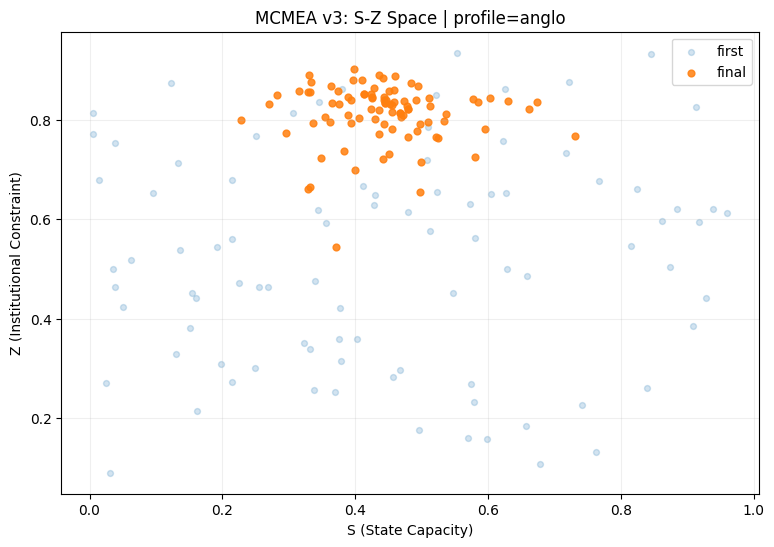

In [25]:

first = history[0]
last = history[-1]

plt.figure(figsize=(9, 6))
plt.scatter([p["S"] for p in first], [p["Z"] for p in first], s=18, alpha=0.20, label="first")
plt.scatter([p["S"] for p in last], [p["Z"] for p in last], s=24, alpha=0.85, label="final")
plt.xlabel("S (State Capacity)")
plt.ylabel("Z (Institutional Constraint)")
plt.title(f"MCMEA v3: S-Z Space | profile={diag['profile']}")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


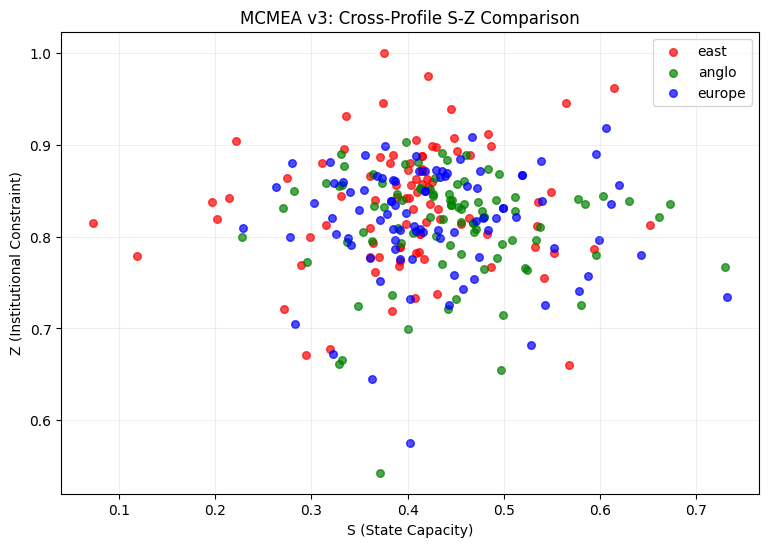

In [27]:
profiles = ["east", "anglo", "europe"]
colors = {
    "east": "red",
    "anglo": "green",
    "europe": "blue"
}

results = {}

# run all three profiles
for pf in profiles:
    history, macro, ctxs, diag = run_mcmea_v3(
        pop_size=90,
        generations=60,
        m_eval=5,
        lambda_robust=1.0,
        seed=7,
        regime_select_mode="robust_max",
        regime_select_temp=1.0,
        profile=pf,
    )
    results[pf] = history[-1]  # final population only

# plot
plt.figure(figsize=(9, 6))

for pf in profiles:
    data = results[pf]
    xs = [p["S"] for p in data]
    ys = [p["Z"] for p in data]

    plt.scatter(
        xs, ys,
        s=30,
        alpha=0.7,
        label=pf,
        color=colors[pf]
    )

plt.xlabel("S (State Capacity)")
plt.ylabel("Z (Institutional Constraint)")
plt.title("MCMEA v3: Cross-Profile S-Z Comparison")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

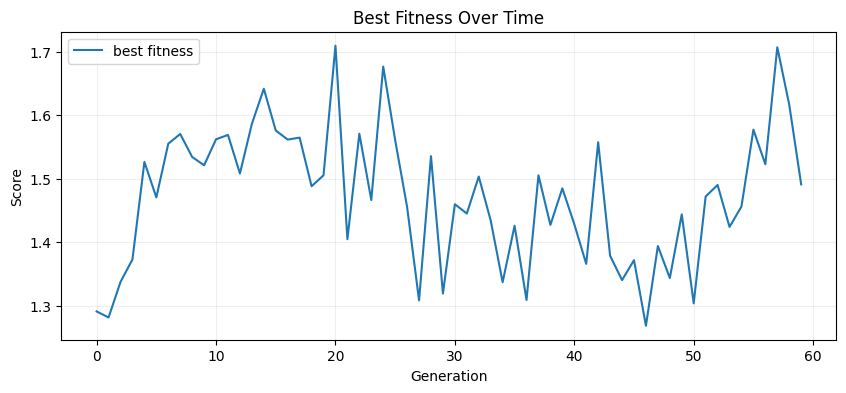

In [14]:

plt.figure(figsize=(10, 4))
plt.plot(diag["best_fitness"], label="best fitness")
plt.xlabel("Generation")
plt.ylabel("Score")
plt.title("Best Fitness Over Time")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


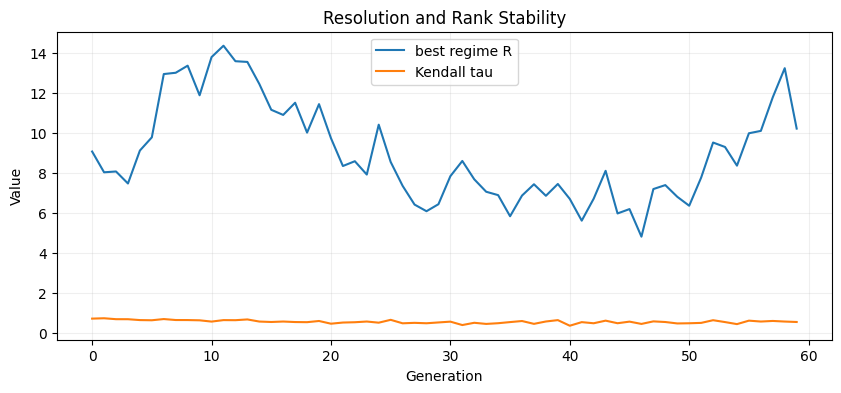

In [15]:

plt.figure(figsize=(10, 4))
plt.plot(diag["best_regime_R"], label="best regime R")
plt.plot(diag["tau_latent_vs_observed"], label="Kendall tau")
plt.xlabel("Generation")
plt.ylabel("Value")
plt.title("Resolution and Rank Stability")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


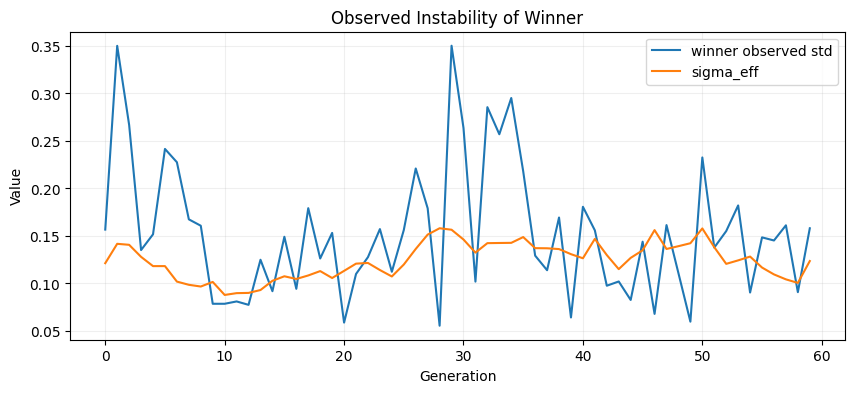

In [16]:

plt.figure(figsize=(10, 4))
plt.plot(diag["best_obs_std"], label="winner observed std")
plt.plot(diag["sigma_eff"], label="sigma_eff")
plt.xlabel("Generation")
plt.ylabel("Value")
plt.title("Observed Instability of Winner")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


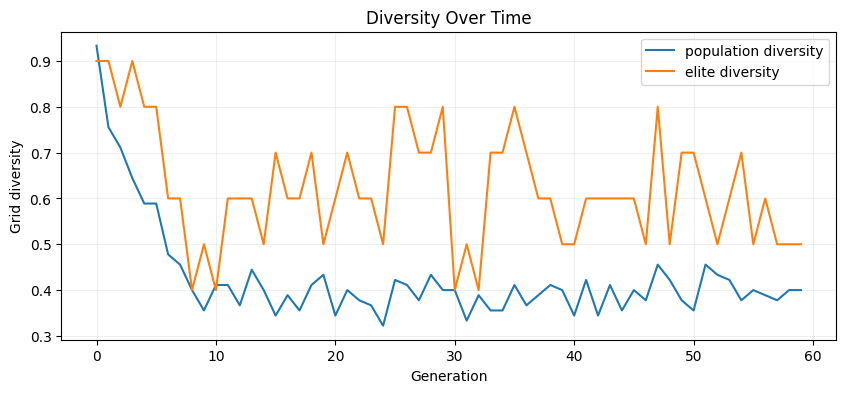

In [17]:

plt.figure(figsize=(10, 4))
plt.plot(diag["pop_diversity"], label="population diversity")
plt.plot(diag["elite_diversity"], label="elite diversity")
plt.xlabel("Generation")
plt.ylabel("Grid diversity")
plt.title("Diversity Over Time")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


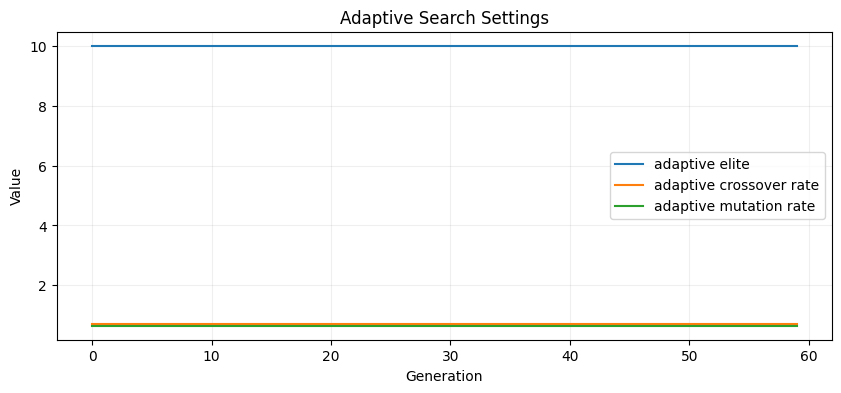

In [18]:

plt.figure(figsize=(10, 4))
plt.plot(diag["adaptive_elite"], label="adaptive elite")
plt.plot(diag["adaptive_cx_rate"], label="adaptive crossover rate")
plt.plot(diag["adaptive_mut_rate"], label="adaptive mutation rate")
plt.xlabel("Generation")
plt.ylabel("Value")
plt.title("Adaptive Search Settings")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


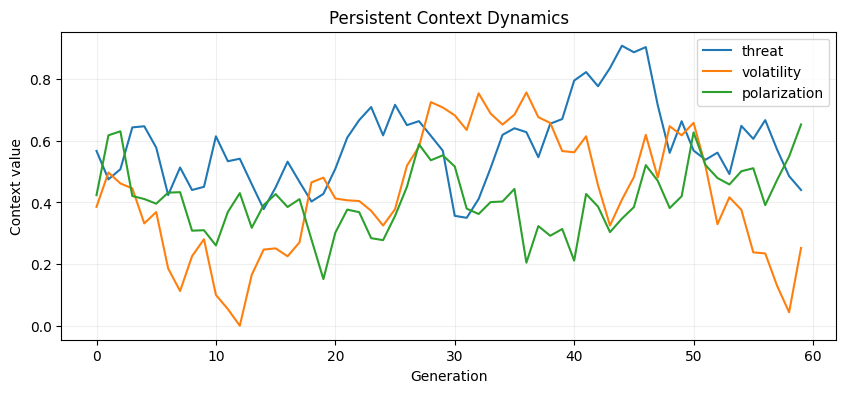

In [19]:

plt.figure(figsize=(10, 4))
plt.plot(diag["ctx_threat"], label="threat")
plt.plot(diag["ctx_volatility"], label="volatility")
plt.plot(diag["ctx_polarization"], label="polarization")
plt.xlabel("Generation")
plt.ylabel("Context value")
plt.title("Persistent Context Dynamics")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


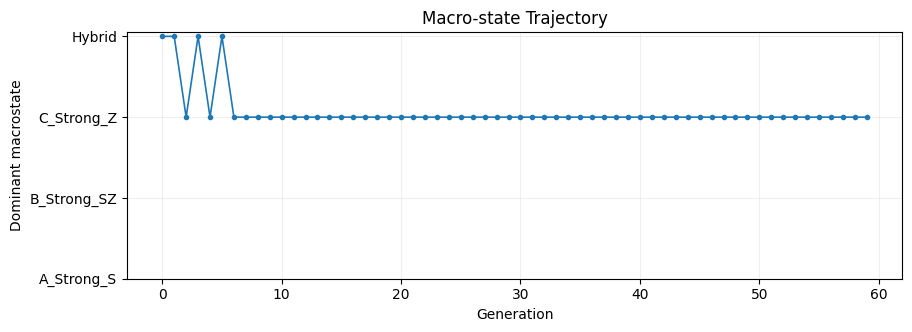

In [20]:

plt.figure(figsize=(10, 3.2))
plt.plot([state_list.index(s) for s in macro], marker="o", markersize=3, linewidth=1.2)
plt.yticks(range(len(state_list)), state_list)
plt.xlabel("Generation")
plt.ylabel("Dominant macrostate")
plt.title("Macro-state Trajectory")
plt.grid(True, alpha=0.2)
plt.show()


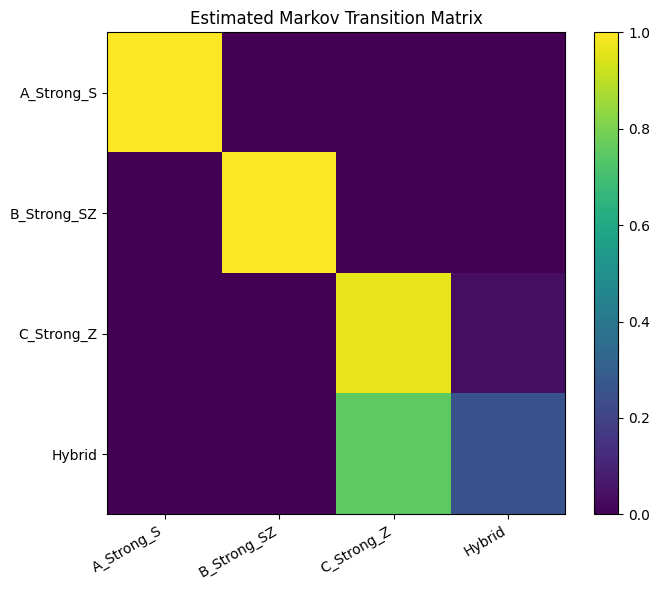

State order: ['A_Strong_S', 'B_Strong_SZ', 'C_Strong_Z', 'Hybrid']

Transition counts C:
 [[ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0 53  2]
 [ 0  0  3  1]]

Transition probabilities P:
 [[1.    0.    0.    0.   ]
 [0.    1.    0.    0.   ]
 [0.    0.    0.964 0.036]
 [0.    0.    0.75  0.25 ]]


In [21]:

P, C = build_markov(macro, state_list)

plt.figure(figsize=(7, 6))
plt.imshow(P, aspect="auto")
plt.xticks(range(len(state_list)), state_list, rotation=30, ha="right")
plt.yticks(range(len(state_list)), state_list)
plt.title("Estimated Markov Transition Matrix")
plt.colorbar()
plt.tight_layout()
plt.show()

print("State order:", state_list)
print("\nTransition counts C:\n", C.astype(int))
print("\nTransition probabilities P:\n", np.round(P, 3))


## Multi-run entropy by profile

In [22]:

seeds = list(range(20, 60))

results_by_profile = {}
for pf in PROFILE_NAMES:
    results_by_profile[pf] = run_many_v3(
        seeds,
        profile=pf,
        pop_size=90,
        generations=50,
        m_eval=5,
        lambda_robust=1.0,
        regime_select_mode="robust_max",
        regime_select_temp=1.0,
    )

for pf, res in results_by_profile.items():
    print(f"Profile = {pf}")
    print(f"  Winner entropy H = {res['H']:.3f}")
    print(f"  Effective winners exp(H) = {res['eff']:.2f}")
    print(f"  Macrostate counts = {res['macro_counts']}")
    print()


Profile = east
  Winner entropy H = 2.367
  Effective winners exp(H) = 10.66
  Macrostate counts = {'A_Strong_S': 34, 'C_Strong_Z': 6}

Profile = anglo
  Winner entropy H = 2.554
  Effective winners exp(H) = 12.86
  Macrostate counts = {'A_Strong_S': 23, 'C_Strong_Z': 17}

Profile = europe
  Winner entropy H = 2.460
  Effective winners exp(H) = 11.71
  Macrostate counts = {'A_Strong_S': 29, 'C_Strong_Z': 11}



## Summary table

In [23]:

summary_df = pd.DataFrame({
    "generation": np.arange(len(diag["best_fitness"])),
    "best_fitness": diag["best_fitness"],
    "best_regime_R": diag["best_regime_R"],
    "best_regime_delta": diag["best_regime_delta"],
    "best_regime_top1": diag["best_regime_top1"],
    "best_regime_top2": diag["best_regime_top2"],
    "best_obs_std": diag["best_obs_std"],
    "sigma_eff": diag["sigma_eff"],
    "tau_latent_vs_observed": diag["tau_latent_vs_observed"],
    "pop_diversity": diag["pop_diversity"],
    "elite_diversity": diag["elite_diversity"],
    "adaptive_elite": diag["adaptive_elite"],
    "adaptive_cx_rate": diag["adaptive_cx_rate"],
    "adaptive_mut_rate": diag["adaptive_mut_rate"],
    "ctx_threat": diag["ctx_threat"],
    "ctx_volatility": diag["ctx_volatility"],
    "ctx_polarization": diag["ctx_polarization"],
})
summary_df.head(12)


,generation,best_fitness,best_regime_R,best_regime_delta,best_regime_top1,best_regime_top2,best_obs_std,sigma_eff,tau_latent_vs_observed,pop_diversity,elite_diversity,adaptive_elite,adaptive_cx_rate,adaptive_mut_rate,ctx_threat,ctx_volatility,ctx_polarization
0,0,1.291352,9.073747,1.101110,C_Strong_Z,A_Strong_S,0.156711,0.121351,0.697378,0.933333,0.9,10,0.7,0.65,0.567391,0.385936,0.423985
1,1,1.281791,8.032479,1.138526,C_Strong_Z,A_Strong_S,0.350164,0.141740,0.715356,0.755556,0.9,10,0.7,0.65,0.475290,0.497343,0.618135
2,2,1.337789,8.073544,1.135885,C_Strong_Z,A_Strong_S,0.266917,0.140692,0.668914,0.711111,0.8,10,0.7,0.65,0.507968,0.461882,0.631128
3,3,1.373135,7.471094,0.956348,C_Strong_Z,A_Strong_S,0.135175,0.128006,0.667416,0.644444,0.9,10,0.7,0.65,0.643847,0.445787,0.420992
4,4,1.526604,9.122982,1.078945,C_Strong_Z,A_Strong_S,0.151749,0.118267,0.623970,0.588889,0.8,10,0.7,0.65,0.647483,0.332178,0.411322
5,5,1.470821,9.785447,1.157399,A_Strong_S,C_Strong_Z,0.241625,0.118278,0.614981,0.588889,0.8,10,0.7,0.65,0.578246,0.368910,0.396114
6,6,1.555302,12.957606,1.321235,C_Strong_Z,A_Strong_S,0.227619,0.101966,0.675406,0.477778,0.6,10,0.7,0.65,0.424202,0.185765,0.431956
7,7,1.570652,13.022621,1.283899,C_Strong_Z,A_Strong_S,0.167493,0.098590,0.626966,0.455556,0.6,10,0.7,0.65,0.513615,0.112626,0.433525
8,8,1.534487,13.378305,1.294706,C_Strong_Z,A_Strong_S,0.160771,0.096777,0.624969,0.400000,0.4,10,0.7,0.65,0.440581,0.225581,0.308497
9,9,1.521349,11.893084,1.208422,C_Strong_Z,A_Strong_S,0.078621,0.101607,0.612484,0.355556,0.5,10,0.7,0.65,0.450886,0.280852,0.309962
